# Aisle & Co. conversion model: feature store and MLOps
MADT 8102 Capstone, Chapter 7: MLOps and Feature Stores

**Business problem (Problem 2, high inquiry and low conversion).** About 14% of inquiries become a booking.
Three in four lost inquiries are closed as "No reply": the couple went silent and the 30-day rule closed
the inquiry. Sales cannot follow up every open inquiry with the same effort. This model scores every open
inquiry each morning with its chance to book, so Sales calls the most promising couples first and reaches
the quiet ones before they drop out.

**What this notebook shows**, in the order of the data science steps of Chapter 7:

| Step (Chapter 7) | Here | Section |
|---|---|---|
| Data extraction | The daily ETL loads the CRM into the warehouse (Chapter 6 pipeline) | 1 |
| Feature store | `feature.inquiry_features`: one feature definition in SQL, point in time; offline store `feature.InquiryFeatures` | 2 |
| Data analysis | Booking rate against the features | 3 |
| Data preparation, training | Time-based split, two candidate models and a baseline | 4 |
| Evaluation, validation | AUC by inquiry age, top-20% capture; the gate against the baseline and the production model | 4 |
| Model registry, metadata | `ml.ModelVersion`: every training run, its data window, metrics, decision and the model itself | 4, 7 |
| Serving | Batch prediction each morning into `ml.InquiryScore`, read by the dashboard's follow-up list | 5 |
| Monitoring | Data drift (PSI) and live accuracy into `ml.DriftCheck`; alerts in `etl.Alert`; retraining | 6 |
| Automation | Airflow: daily `ml_features → ml_score → ml_monitor` after the ETL, weekly `aisleco_weekly_train` | 7 |

**The data is simulated** (`AisleCo_MultiZone_Architecture_v3.ipynb`): three years of inquiries, 2024 to 2026,
where each couple's hidden readiness to book drives what the CRM records. The assumptions are listed in
that notebook. The model's accuracy therefore reflects those assumptions, not real couples. What the notebook
demonstrates is the pipeline: with the real CRM, the same code learns the real drivers.

In [1]:
import sys, time, logging
from dataclasses import replace
from datetime import date, timedelta
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
T0 = time.perf_counter()

ROOT = Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]
from etl import db, pipeline
from etl.config import Config
from etl.__main__ import init_dw
from load_snapshot import load
from ml import features as F, train as T, score as S, monitor as M

logging.basicConfig(level=logging.ERROR)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
INK, INK2, EDGE, BLUE, ORANGE, RED, GREEN = "#0b0b0b", "#52514e", "#9a9893", "#2a78d6", "#eb6834", "#b03a2e", "#1a7f37"

# separate databases, so the ETL demo's aisleco_crm / aisleco_dw are not touched
cfg = replace(Config(), crm_dsn="dbname=aisleco_crm_ml", dw_dsn="dbname=aisleco_dw_ml", landing_dir=ROOT / "data" / "landing_ml")

def dw(sql, params=None):
    with db.connect(cfg.dw_dsn, cfg, autocommit=True) as c:
        return pd.DataFrame(c.execute(sql, params).fetchall())

def with_dw(fn, *args, **kw):
    with db.connect(cfg.dw_dsn, cfg) as c:
        out = fn(c, *args, **kw); c.commit()
        return out

## 1. Data extraction: the warehouse the model reads

The simulated CRM (three years, as of 15 Jan 2027) goes through the Chapter 6 pipeline, as every morning in
production. The model reads only the warehouse: Silver (`stg`, the cleaned CRM rows with their timestamps)
for features, and nothing from the CRM directly.

In [2]:
ZONES = ROOT / "data" / "sim" / "zones_v3"
rows = load(ZONES, 1, cfg)
init_dw(cfg, drop=True)
run = pipeline.run(cfg, date(2027, 1, 15), "full")
print(f"CRM rows loaded: {sum(rows.values()):,}; ETL run {run} succeeded")
dw('''SELECT extract(year FROM "InquiryDate")::int AS inquiry_year, count(*) AS inquiries,
             count(*) FILTER (WHERE "Status" = 'Converted') AS booked,
             count(*) FILTER (WHERE "LostReason" = 'No reply') AS no_reply,
             count(*) FILTER (WHERE "Status" NOT IN ('Converted','Lost')) AS still_open
      FROM stg."Inquiry" GROUP BY 1 ORDER BY 1''')

warehouse aisleco_dw_ml created (DW v7) with 27 data-quality rules


CRM rows loaded: 27,596; ETL run 1 succeeded


,inquiry_year,inquiries,booked,no_reply,still_open
0,2024,638,108,402,0
1,2025,645,87,423,0
2,2026,622,78,395,20


## 2. Feature store

A feature store sits between the raw data and the models, so that training and prediction use the same
features (Chapter 7). Here it is three objects in the warehouse, in plain PostgreSQL (`sql/ml_feature_store.sql`):

* `feature.inquiry_features(ids, cutoffs)`: the only definition of the features. For each inquiry and
  cutoff time it uses only rows dated before the cutoff. Training calls it with past cutoffs, the daily
  scoring with today, so both get features computed the same way.
* `feature."InquiryFeatures"`: the offline store, one row per open inquiry per scoring day.
* `feature."InquiryLabel"`: the outcome (booked or not) of closed inquiries, and when it became known.

The design of the slides, entity + time index + features:

| Index | Time index | Features |
|---|---|---|
| `InquiryID` | `AsOf` (the cutoff) | channel, budget, package type, wedding date given, lead days, peak or auspicious date, our reply time, couple messages (total and in the first 24 h), hours since the couple last wrote, consulted, quoted, quote share of budget, age in days |

**Point in time.** One booked inquiry, as the store sees it at different ages. The features grow as the couple
writes, gets a consultation and a quote. After the booking it is no longer open, so it is not returned.

In [3]:
lab = dw('SELECT * FROM feature."InquiryLabel" WHERE "Booked" = 1 AND "ClosedAt" - "InquiryDate" > interval \'25 days\' ORDER BY "InquiryID" LIMIT 1').iloc[0]
start = pd.Timestamp(lab.InquiryDate).normalize()
cuts = [start + pd.Timedelta(days=k) for k in (1, 7, 14, 21)] + [pd.Timestamp(lab.ClosedAt) + pd.Timedelta(days=1)]
with db.connect(cfg.dw_dsn, cfg) as c:
    pit = F.compute(c, [int(lab.InquiryID)] * len(cuts), [x.to_pydatetime() for x in cuts])
print(f"Inquiry {lab.InquiryID}: received {lab.InquiryDate:%d %b %Y %H:%M}, booked {lab.ClosedAt:%d %b %Y}. "
      f"Asked at {len(cuts)} cutoffs, returned at {len(pit)} (the last cutoff is after the booking).")
pit.set_index("AsOf").T

Inquiry 1: received 01 Jan 2024 13:28, booked 26 Jan 2024. Asked at 5 cutoffs, returned at 4 (the last cutoff is after the booking).


AsOf,2024-01-02,2024-01-08,2024-01-15,2024-01-22
InquiryID,1,1,1,1
AgeDays,1.0,7.0,14.0,21.0
Channel,Facebook,Facebook,Facebook,Facebook
BudgetRange,300k-500k,300k-500k,300k-500k,300k-500k
PackageType,None,None,None,None
HasRequestedDate,1.0,1.0,1.0,1.0
LeadDays,89.0,89.0,89.0,89.0
PeakDate,0.0,0.0,0.0,0.0
ResponseMinutes,216.0,216.0,216.0,216.0
HasChat,1.0,1.0,1.0,1.0


**Training examples.** Each closed inquiry is taken as it looked 1, 7, 14 and 30 days after it arrived, while it
was still open, and joined with its later outcome. This point-in-time join is what keeps the outcome out of the
features: a feature can only use what had happened by that age.

In [4]:
ASOF0 = date(2025, 10, 1)       # the first model is trained with what was known on this date
with db.connect(cfg.dw_dsn, cfg) as c:
    ts = F.training_set(c, ASOF0)
print(f"{len(ts):,} training rows from {ts.InquiryID.nunique():,} closed inquiries (known on {ASOF0}); booked share {ts.Booked.mean():.1%}")
ts.groupby("AgeDays").agg(rows=("Booked", "size"), booked_share=("Booked", "mean")).round(3)

4,036 training rows from 1,097 closed inquiries (known on 2025-10-01); booked share 13.5%


,rows,booked_share
AgeDays,,
1.0,1097,0.156
7.0,1096,0.156
14.0,1062,0.151
30.0,781,0.054


## 3. Data analysis

The booking rate against some features, on the training rows. Channel and the couple's own behaviour (how many
messages, how long they have been silent) separate bookers from the rest; that is what the model can use.

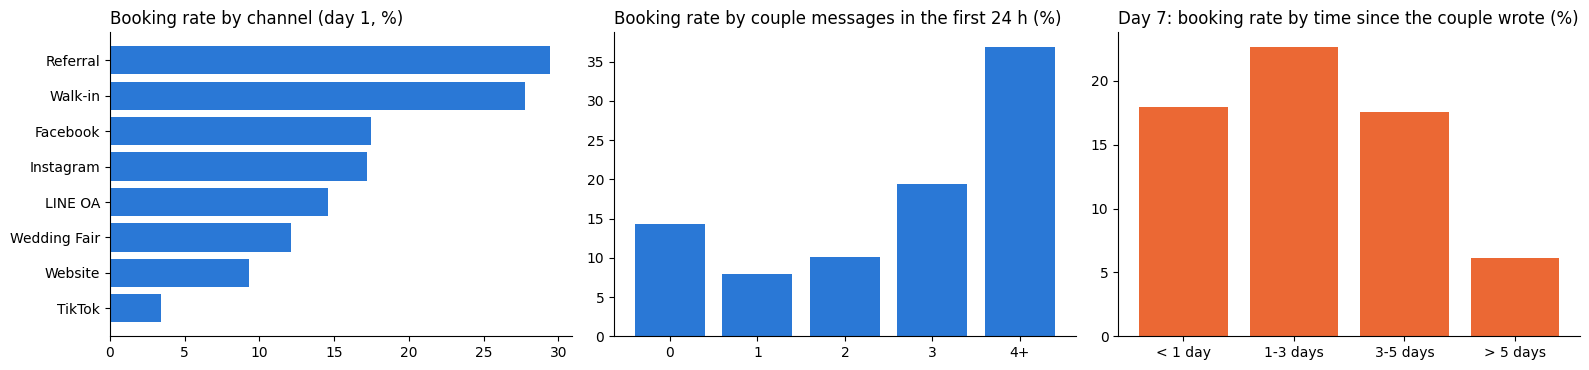

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
d1 = ts[ts.AgeDays == 1]
r = d1.groupby("Channel").Booked.mean().sort_values()
ax[0].barh(r.index, r.values * 100, color=BLUE); ax[0].set_title("Booking rate by channel (day 1, %)", loc="left")
b = d1.assign(m=d1.CoupleMsgs24h.clip(upper=4)).groupby("m").Booked.mean()
ax[1].bar([str(int(i)) if i < 4 else "4+" for i in b.index], b.values * 100, color=BLUE)
ax[1].set_title("Booking rate by couple messages in the first 24 h (%)", loc="left")
d7 = ts[(ts.AgeDays == 7) & ts.HoursSilent.notna()]
s = d7.groupby(pd.cut(d7.HoursSilent, [0, 24, 72, 120, 1000], labels=["< 1 day", "1-3 days", "3-5 days", "> 5 days"]), observed=True).Booked.mean()
ax[2].bar(s.index.astype(str), s.values * 100, color=ORANGE); ax[2].set_title("Day 7: booking rate by time since the couple wrote (%)", loc="left")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 4. Training, evaluation and validation

`ml.train.train(as_of)` runs the whole automated step:

1. **Split by time**, never at random: test = inquiries received 270 to 90 days before the as-of date
   (old enough for their outcome to be known), train = everything before.
2. **Two candidates**: logistic regression and gradient boosting, the same preprocessing for both (one-hot for
   categories; missing values imputed with a "was missing" flag, since a missing reply time or wedding date is
   itself informative).
3. **Baseline**: each channel's past booking rate. A model is only worth running if it beats this clearly.
4. **Evaluation** on the test window: AUC (overall and by inquiry age), PR-AUC, and the share of all bookings
   found in the top 20% of scores (what Sales gets if it calls one couple in five).
5. **Validation gate**: the best candidate is promoted only if its AUC is at least 0.05 above the baseline, and
   not below the production model on test inquiries that model never saw.
6. **Registry**: the result, promoted or not, is written to `ml."ModelVersion"` with its data windows, metrics,
   decision, the training distributions (for drift checks) and the model itself. The promoted model is refit on
   train + test.

In [6]:
r0 = with_dw(T.train, ASOF0)
print(f"model v{r0['version']} ({r0['algorithm']}): {r0['status']} - {r0['decision']}")
m = pd.DataFrame({**{k: v for k, v in r0["candidates"].items()}, "baseline (channel rate)": r0["baseline"]}).T
m = m.join(pd.DataFrame(m.pop("auc_by_day").tolist(), index=m.index).add_prefix("AUC day "))
m

model v1 (logistic regression): production - AUC 0.798 vs baseline 0.56; refit on train + test


,auc,pr_auc,top20_capture,brier,AUC day 1,AUC day 7,AUC day 14,AUC day 30
logistic regression,0.798,0.375,0.513,0.0965,0.663,0.808,0.828,0.901
gradient boosting,0.793,0.331,0.506,0.098,0.670,0.774,0.825,0.912
baseline (channel rate),0.56,0.155,0.26,0.1076,0.557,0.556,0.591,0.449


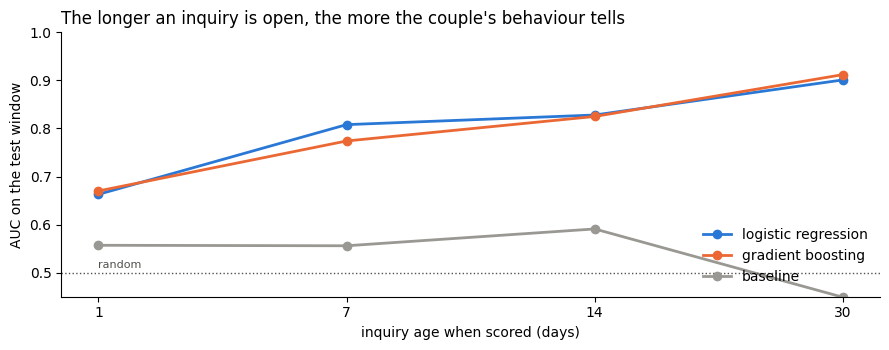

On day 1 the model has only the channel, budget, package, wedding date, our reply time and the first messages (AUC 0.663). By day 14 the couple's replies and silences are visible (AUC 0.828). The top 20% of scores contain 51% of the bookings.


In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
days = list(r0["baseline"]["auc_by_day"])
for (name, res), color in zip([*r0["candidates"].items(), ("baseline", r0["baseline"])], [BLUE, ORANGE, EDGE]):
    ax.plot(days, [res["auc_by_day"][d] for d in days], marker="o", color=color, lw=2, label=name)
ax.axhline(0.5, color=INK2, ls=":", lw=1); ax.text(0, 0.51, "random", fontsize=8, color=INK2)
ax.set_xlabel("inquiry age when scored (days)"); ax.set_ylabel("AUC on the test window"); ax.set_ylim(0.45, 1)
ax.legend(frameon=False, loc="lower right"); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("The longer an inquiry is open, the more the couple's behaviour tells", loc="left"); plt.tight_layout(); plt.show()
print(f"On day 1 the model has only the channel, budget, package, wedding date, our reply time and the first messages "
      f"(AUC {r0['test']['auc_by_day']['1']}). By day 14 the couple's replies and silences are visible "
      f"(AUC {r0['test']['auc_by_day']['14']}). The top 20% of scores contain {r0['test']['top20_capture']:.0%} of the bookings.")

## 5. Serving: the morning follow-up list, and does it work?

Each morning after the ETL, `features.materialise` stores today's features of every open inquiry and
`score.score` adds the production model's chance to book, banded High (top 20% of training scores), Medium and
Low. The dashboard's *Follow-up today* tab reads `mart.v_followup_list`.

To see the model in use, the next cell replays the mornings from October 2025 to January 2027, once a week,
with the model trained on 1 Oct 2025: store features, score, monitor. When the monitor raises an alert, the
model is retrained with what is known that day (at most every 8 weeks), as the weekly training DAG would.

In [8]:
mondays = pd.date_range("2025-10-06", "2027-01-11", freq="7D").date
last_train, log = ASOF0, []
for d in mondays:
    with db.connect(cfg.dw_dsn, cfg) as c:
        n = F.materialise(c, d); S.score(c, d)
        checks = {name: (v, st) for name, v, st, _ in M.monitor(c, d)}
        retrain = any(st == "alert" for _, st in checks.values()) and (d - last_train).days >= 56
        if retrain:
            r = T.train(c, d); last_train = d
        c.commit()
    log.append({"week": d, "open": n, "PSI Channel": checks.get("PSI Channel", (None,))[0],
                "status": checks.get("PSI Channel", (None, "n/a"))[1], "live AUC": checks["live AUC"][0],
                "retrained": f"v{r['version']} {r['status']}" if retrain else ""})
log = pd.DataFrame(log)
print(f"{len(mondays)} mornings replayed; {(log.retrained != '').sum()} retrainings")
log[log.retrained != ""]

67 mornings replayed; 4 retrainings


,week,open,PSI Channel,status,live AUC,retrained
19,2026-02-16,71,0.203,alert,0.869,v2 production
27,2026-04-13,66,0.374,alert,0.883,v3 production
35,2026-06-08,60,0.238,alert,0.889,v4 production
63,2026-12-21,33,0.205,alert,0.889,v5 production


In [9]:
band = dw('''SELECT s."Band", count(*) AS scored, round(avg(l."Booked"), 3) AS booked_later
             FROM ml."InquiryScore" s JOIN feature."InquiryLabel" l USING ("InquiryID")
             GROUP BY 1 ORDER BY 3 DESC''')
display(band)
b = band.set_index("Band").booked_later.astype(float)
print(f"Couples in the High band booked {b['High']:.0%} of the time, Medium {b['Medium']:.0%}, Low {b['Low']:.0%} "
      f"(every weekly score whose outcome is now known). Calling the High band first is where Sales' time pays off.")

,Band,scored,booked_later
0,High,563,0.389
1,Medium,758,0.127
2,Low,1905,0.010


Couples in the High band booked 39% of the time, Medium 13%, Low 1% (every weekly score whose outcome is now known). Calling the High band first is where Sales' time pays off.


## 6. Monitoring: data drift and live accuracy

`monitor.monitor(as_of)` compares the inquiries of the last 120 days (as they looked on day 1) with the data the
production model was trained on (Chapter 7, data distribution shift). 120 days is longer than the longest gap
between two wedding fairs (99 days): with a shorter window, a stretch without a fair would look like drift
because fair leads would vanish from it.

* **PSI** (population stability index) for channel, budget, package type, and deciles of lead days, reply time
  and first-day messages. Below 0.1 is stable, 0.1 to 0.2 a warning, 0.2 or more an alert.
* **Missing rates**: a feature that suddenly goes missing more often would make the model predict from its
  imputed value (Chapter 7, "missing as a feature").
* **Live AUC**: the scores given 30 to 180 days ago, against the outcomes known now. A drop of 0.1 below the test
  AUC is an alert.

In 2026 a TikTok campaign changed who writes to us: TikTok went from about 6% of inquiries to about 19%, and those
couples book far less often. The channel PSI catches it.

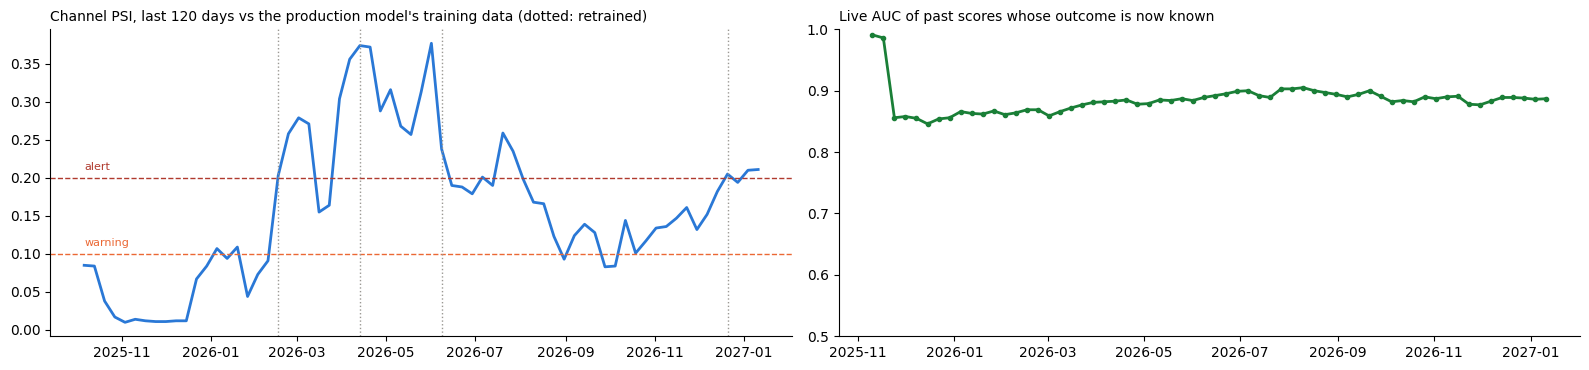

21 weekly drift alerts written to etl.Alert; the first three:


,Message
0,model v1 drift on 2026-02-16: PSI Channel = 0.203; retrain and review
1,"model v2 drift on 2026-02-23: PSI Channel = 0.258, missing HoursSilent = 0.161; retrai..."
2,"model v2 drift on 2026-03-02: PSI Channel = 0.279, missing HoursSilent = 0.163; retrai..."


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 3.8))
ax[0].plot(log.week, log["PSI Channel"], color=BLUE, lw=2)
ax[0].axhline(0.1, color=ORANGE, ls="--", lw=1); ax[0].axhline(0.2, color=RED, ls="--", lw=1)
ax[0].text(log.week.iloc[0], 0.21, "alert", color=RED, fontsize=8); ax[0].text(log.week.iloc[0], 0.11, "warning", color=ORANGE, fontsize=8)
for w in log.week[log.retrained != ""]:
    ax[0].axvline(w, color=EDGE, lw=1, ls=":")
ax[0].set_title("Channel PSI, last 120 days vs the production model's training data (dotted: retrained)", loc="left", fontsize=10)
live = log.dropna(subset=["live AUC"])
ax[1].plot(live.week, live["live AUC"].astype(float), color=GREEN, lw=2, marker=".")
ax[1].set_ylim(0.5, 1); ax[1].set_title("Live AUC of past scores whose outcome is now known", loc="left", fontsize=10)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
alerts = dw('''SELECT "Message" FROM etl."Alert" WHERE "Message" LIKE 'model %%' ORDER BY "AlertID"''')
print(f"{len(alerts)} weekly drift alerts written to etl.Alert; the first three:"); alerts.head(3)

Two things to read from this. The alert does not stop right after a retraining: a model can only learn from
inquiries whose outcome is known, so its training data trails the new channel mix by about three months, and the
PSI falls only as 2026 inquiries enter the training data. And drift is not the same as a worse model: the live AUC
stayed high, because the model already knew that TikTok couples book less. The alert's job is to make someone
look; the gate decides whether a retrained model is better.

## 7. The registry, today's list, and the automation

Every training run is in the registry, including the ones the gate rejected, with the reason. On the as-of
date of the data (15 Jan 2027) the weekly training runs once more and the morning steps produce today's list.

In [11]:
with db.connect(cfg.dw_dsn, cfg) as c:
    final = T.train(c, date(2027, 1, 15)); F.materialise(c, date(2027, 1, 15)); S.score(c, date(2027, 1, 15))
    today = M.monitor(c, date(2027, 1, 15)); c.commit()
print(f"weekly training on 15 Jan 2027: model v{final['version']} {final['status']} - {final['decision']}\n")
display(dw('SELECT * FROM mart.v_model_versions ORDER BY "Version"'))
dw('SELECT "InquiryID", "Band", "Score", "Channel", "AgeDays", "HoursSilent", "CoupleMsgs", "Consulted", "Quoted" '
   'FROM mart.v_followup_list ORDER BY "Score" DESC')

weekly training on 15 Jan 2027: model v6 production - AUC 0.868 vs baseline 0.68; production v5 has no unseen test rows to compare; refit on train + test



,Version,TrainedAt,trained_on_data_to,Algorithm,Status,TrainRows,TestRows,test_auc,baseline_auc,top20_capture,Decision
0,1,2026-11-08 10:22:57.579225,2025-10-01,logistic regression,retired,2364,1270,0.798,0.56,0.513,AUC 0.798 vs baseline 0.56; refit on train + test
1,2,2026-11-08 10:22:58.291910,2026-02-16,logistic regression,retired,3307,1224,0.846,0.604,0.638,AUC 0.846 vs baseline 0.604; vs production v1: 0.855 vs 0.845 on 345 unseen rows; refi...
2,3,2026-11-08 10:22:58.819148,2026-04-13,logistic regression,retired,3702,1064,0.839,0.548,0.645,AUC 0.839 vs baseline 0.548; production v2 has no unseen test rows to compare; refit o...
3,4,2026-11-08 10:22:59.414090,2026-06-08,logistic regression,retired,4096,1098,0.88,0.57,0.721,AUC 0.88 vs baseline 0.57; production v3 has no unseen test rows to compare; refit on ...
4,5,2026-11-08 10:23:00.290749,2026-12-21,gradient boosting,retired,5396,1059,0.883,0.689,0.679,AUC 0.883 vs baseline 0.689; vs production v4: 0.875 vs 0.868 on 595 unseen rows; refi...
5,6,2026-11-08 10:23:01.243032,2027-01-15,gradient boosting,production,5536,1056,0.868,0.68,0.629,AUC 0.868 vs baseline 0.68; production v5 has no unseen test rows to compare; refit on...


,InquiryID,Band,Score,Channel,AgeDays,HoursSilent,CoupleMsgs,Consulted,Quoted
0,1902,High,0.6292,Referral,17,379.3,15,1,1
1,1893,Medium,0.1917,Walk-in,26,None,0,1,1
2,1903,Medium,0.1225,Referral,16,301.9,11,1,0
3,1883,Medium,0.1222,TikTok,34,634.8,12,1,1
4,1892,Medium,0.1109,Referral,27,542.0,11,1,1
5,1904,Medium,0.0837,TikTok,16,94.0,12,1,0
6,1899,Medium,0.0751,LINE OA,22,452.6,12,0,0
7,1886,Low,0.0270,Instagram,30,587.6,12,1,0
8,1885,Low,0.0171,LINE OA,30,576.7,11,1,0
9,1905,Low,0.0119,Instagram,15,296.8,8,0,0


**Automation (Airflow).** The same functions run in production as tasks, through the command line `python -m ml`:

* `aisleco_daily_etl`: the 11 ETL steps, then `ml_features → ml_score → ml_monitor` (02:00 every day).
* `aisleco_weekly_train`: `ml train` every Sunday at 04:00; also triggered by hand after a drift alert.

**Dashboard.** `dashboard/app.py` (Streamlit) reads the `mart` views: Problem 1 capacity, Problem 2 conversion and
no-reply rate, the follow-up list, and model health. Run it locally against this notebook's warehouse:

```bash
ETL_DW_DSN=dbname=aisleco_dw_ml .venv/bin/streamlit run dashboard/app.py
```

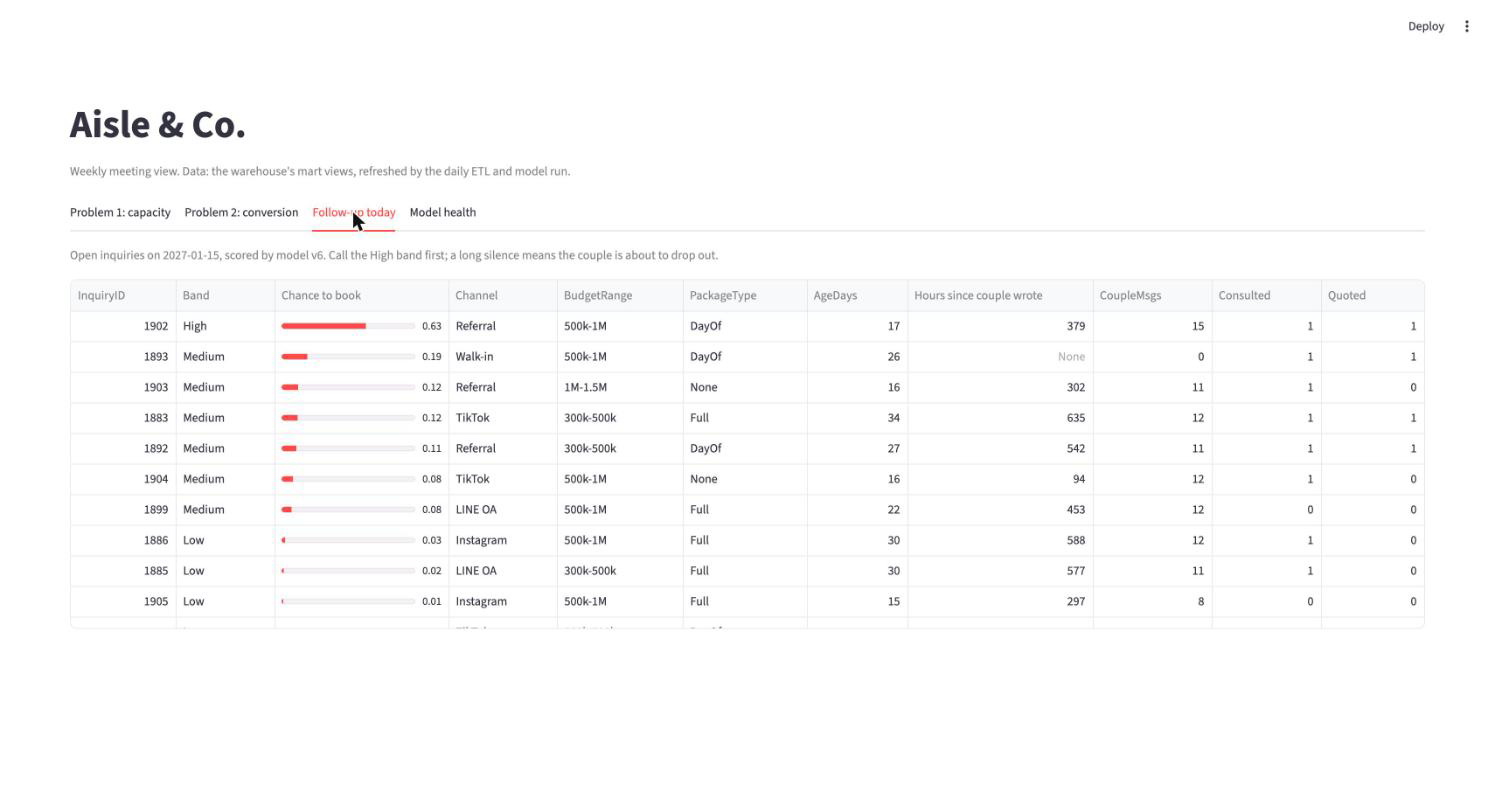

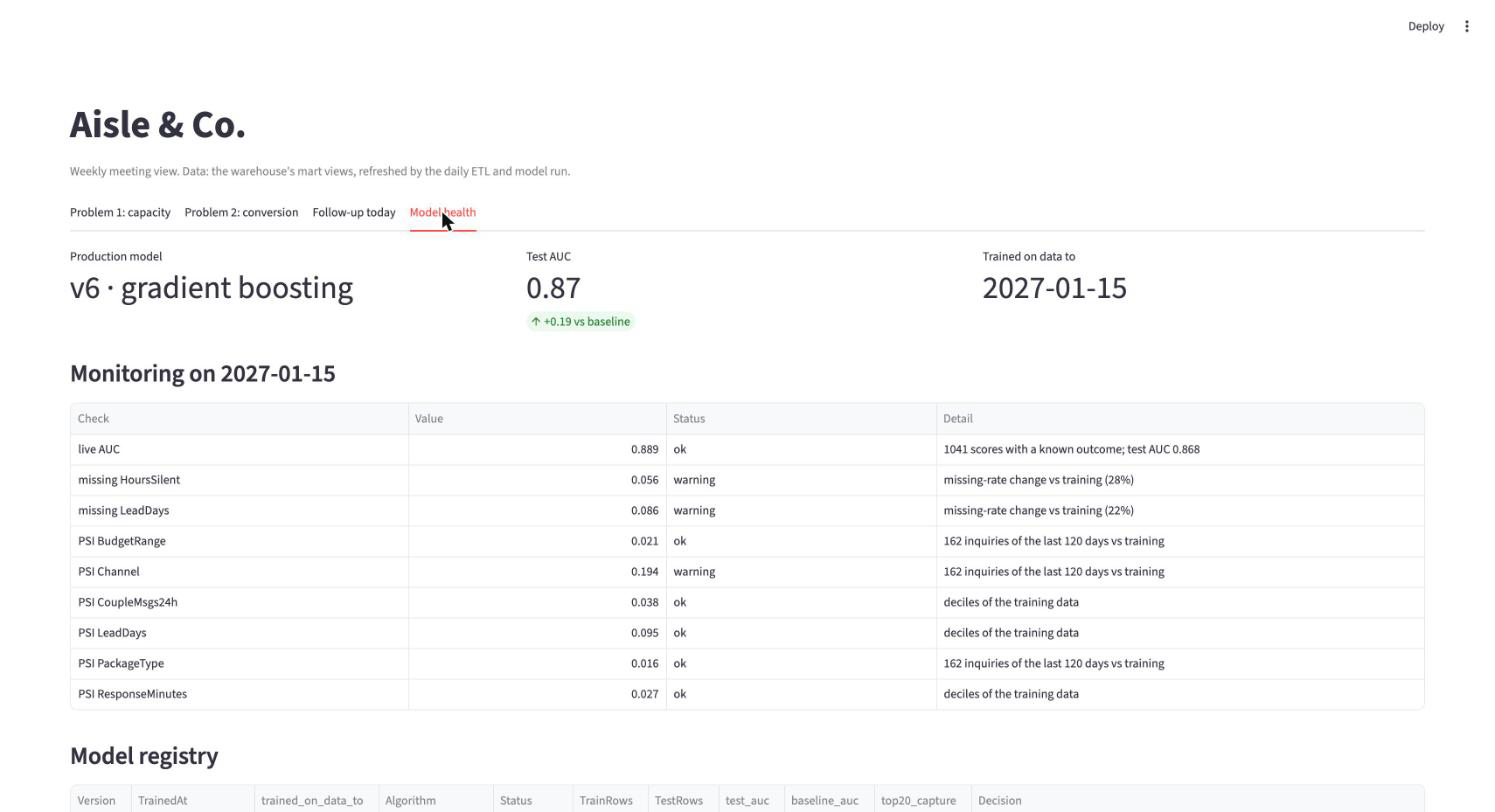

In [12]:
from IPython.display import Image, display
for f in ["dashboard_followup.png", "dashboard_model_health.png"]:
    p = ROOT / "docs" / f
    if p.exists():
        display(Image(filename=str(p), width=1100))

## 8. Where this sits on the MLOps levels of Chapter 7

| Level | What it needs | This project |
|---|---|---|
| 0: manual | Scripts and notebooks, manual hand-over | Passed: nothing here is a manual step |
| 1: ML pipeline automation | Automated training pipeline, continuous training on new data, feature store, metadata store and model registry, validation before deployment, monitoring that triggers retraining | **Yes**: weekly and drift-triggered training, `feature` schema, `ml.ModelVersion`, the gate, `ml.DriftCheck` + `etl.Alert` |
| 2: CI/CD of the pipeline | Each code change to the pipeline built, tested and deployed automatically | Partly: 38 automated tests (5 for the model) run with one command, but nothing runs them on each push yet. A GitHub Actions workflow running `pytest` against a PostgreSQL service would be the next step |

Known limits: descriptive fields (channel, budget, package, wedding date) are read as they are now, not as they
were on past dates, because the CRM keeps no history for them; event times (messages, consultation, quote,
booking) are exact. From the first day in production the offline store keeps every day's features, so this
limit fades with time. The data is simulated, so the accuracy shown is that of the simulation's assumptions.

In [13]:
print(f"Notebook run time: {time.perf_counter() - T0:.0f} s")

Notebook run time: 8 s
